In [27]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [28]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.05     # proximitized Ge
MEFF_SM = 0.05     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
subband energies= 0.30505912614720065 0.915177378441602
4t= 122.02365045888027
mu =  0.3660709513766408


In [29]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
XCT = np.linspace((NSC-200)*AX, (NSC+NSM+200)*AX, 51)
YCT = M/2*AY

print('y charge trap =', YCT)

ZCT = 50
ZIM = 64
Ep = np.empty((XCT.shape[0],K_NUM))

for i in range(XCT.shape[0]):

    H = ModCT.H_sys(PHI, 'cu', XCT[i], YCT, ZCT, ZIM)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    if i %5 ==0 :
        print(Ep[i,:])

np.save('cubic_E_vs_xct_Zdiff_{}_greater_length_beyond_sm.npy'.format(ZIM-ZCT), Ep)

y charge trap = 150.0
[-0.55914749 -0.55857635 -0.11309457 -0.11271594  0.11271594  0.11309457
  0.55857635  0.55914749]
[-0.55933033 -0.55876022 -0.11288424 -0.1125064   0.1125064   0.11288424
  0.55876022  0.55933033]
[-0.55987532 -0.55930816 -0.1122815  -0.11190595  0.11190595  0.1122815
  0.55930816  0.55987532]
[-0.56249531 -0.56194145 -0.10968145 -0.10931629  0.10931629  0.10968145
  0.56194145  0.56249531]
[-0.61533186 -0.61494982 -0.08712658 -0.08689585  0.08689585  0.08712658
  0.61494982  0.61533186]
[-0.75065994 -0.75060649 -0.64267765 -0.64263011  0.64263011  0.64267765
  0.75060649  0.75065994]
[-0.62132526 -0.62095688 -0.08659796 -0.08637775  0.08637775  0.08659796
  0.62095688  0.62132526]
[-0.56263301 -0.56207981 -0.10955463 -0.10918999  0.10918999  0.10955463
  0.56207981  0.56263301]
[-0.55989694 -0.55932989 -0.1122582  -0.11188274  0.11188274  0.1122582
  0.55932989  0.55989694]
[-0.55933662 -0.55876654 -0.11287709 -0.11249928  0.11249928  0.11287709
  0.55876654  0.

In [32]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\cubic_E_vs_xct_Zdiff_0.20000000000000284.npy")

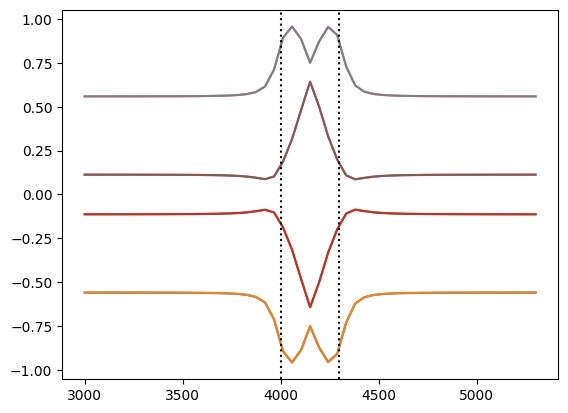

In [30]:
plt.plot(XCT, Ep[:, :])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

In [25]:
print(XCT)

[   0.          244.11764706  488.23529412  732.35294118  976.47058824
 1220.58823529 1464.70588235 1708.82352941 1952.94117647 2197.05882353
 2441.17647059 2685.29411765 2929.41176471 3173.52941176 3417.64705882
 3661.76470588 3905.88235294 4150.         4394.11764706 4638.23529412
 4882.35294118 5126.47058824 5370.58823529 5614.70588235 5858.82352941
 6102.94117647 6347.05882353 6591.17647059 6835.29411765 7079.41176471
 7323.52941176 7567.64705882 7811.76470588 8055.88235294 8300.        ]


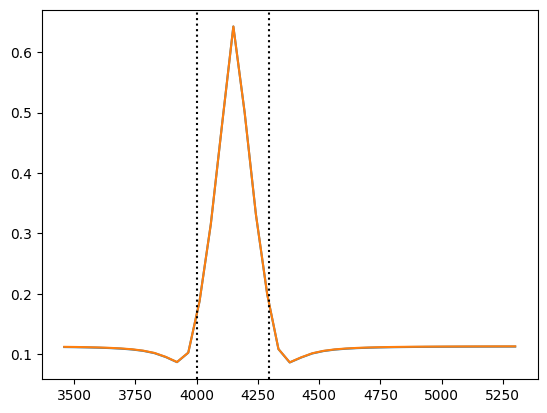

In [31]:
plt.plot(XCT[10:], Ep[10:, K_NUM//2:K_NUM//2+2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

In [33]:
K_NUM//2+1

5

In [34]:
K_NUM//2

4

(0.0, 0.0004543527688092241)

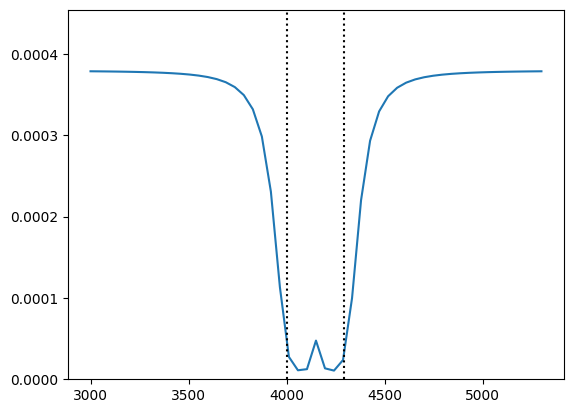

In [32]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

In [9]:
cubic_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)



In [10]:
print(max_spin_split-min_spin_split)

0.00014755373977248798


In [11]:
percent_spin_split = (max_spin_split-min_spin_split)/max_spin_split

In [12]:
print(percent_spin_split)

0.9347044126909262


(0.0, 0.00018943367049828463)

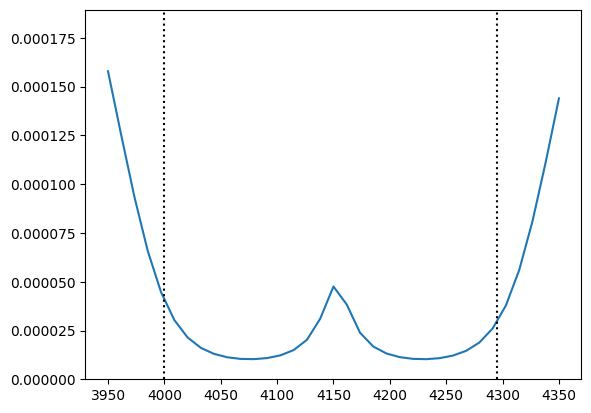

In [7]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

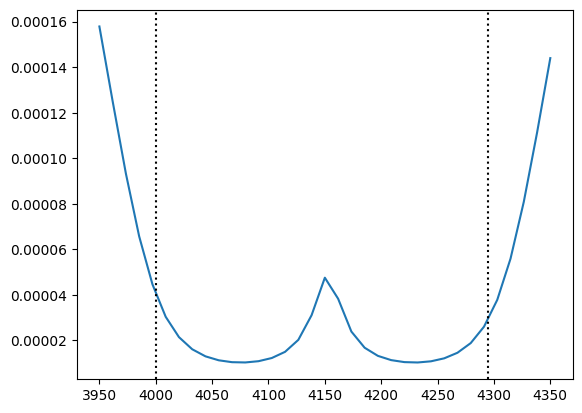

In [8]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

In [19]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\cubic_E_vs_xct_V1.npy")

(0.0, 0.00014110027318041672)

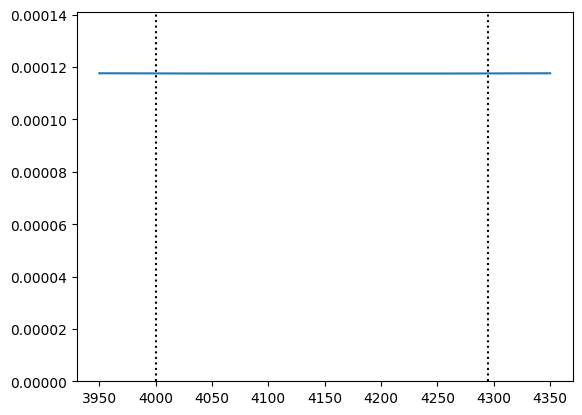

In [20]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

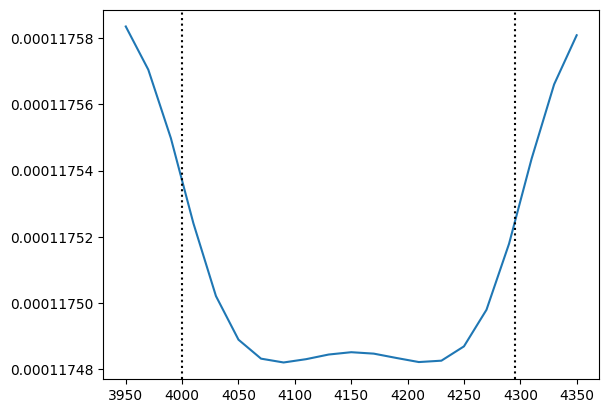

In [21]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))